In [1]:
import pandas as pd

df = pd.read_csv("Trees.csv")
df.head()

/scratch/slurm-45815/ipykernel_1196265/2897429244.py:3: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Trees.csv")


,_id,id,address_number,street,common_name,scientific_name,height,width,growth_space_length,growth_space_width,...,neighborhood,council_district,ward,tract,public_works_division,pli_division,police_zone,fire_zone,latitude,longitude
0,1,754166088,7428.0,MONTICELLO ST,Stump,Stump,0.0,0.0,10.0,2.0,...,Homewood North,9.0,13.0,4.200313e+10,2.0,13.0,5.0,3-17,40.458169,-79.889724
1,2,1946899269,220.0,BALVER AVE,Linden: Littleleaf,Tilia cordata,0.0,0.0,99.0,99.0,...,Oakwood,2.0,28.0,4.200356e+10,5.0,28.0,6.0,1-19,40.429269,-80.067868
2,3,1431517397,2822.0,SIDNEY ST,Maple: Red,Acer rubrum,22.0,6.0,6.0,3.0,...,South Side Flats,3.0,16.0,4.200316e+10,3.0,16.0,3.0,4-24,40.426797,-79.965035
3,4,994063598,608.0,SUISMON ST,Maple: Freeman,Acer x freemanii,25.0,10.0,3.0,3.0,...,East Allegheny,1.0,23.0,4.200356e+10,1.0,23.0,1.0,1-6,40.455503,-79.999276
4,5,1591838573,1135.0,N NEGLEY AVE,Maple: Norway,Acer platanoides,52.0,13.0,99.0,99.0,...,Highland Park,7.0,11.0,4.200311e+10,2.0,11.0,5.0,3-9,40.476667,-79.924106


**Important Note** - This file has not been updated since 2020, So some of the numbers may be off, but for the data analysis I will be Using the numbers from 2020 as it is sufficient. 

**Coding To Get Metrics & Data to Use**

In [2]:
print("There are" , len(df), "total trees.")

print()
print() 

print("Most common tree's, with the type and number of them.")
print() 
tree_top_10 = df["common_name"].value_counts().head(10)
for tree_types, count in tree_top_10.items():
    print(tree_types, ":", count)

print() 
print() 
print("Neighborhoods and the tree amounts per neighborhood")
print() 
trees_per_neighborhood = df["neighborhood"].value_counts()
for place, count in trees_per_neighborhood.items():
    print(place, ":", count)
print() 
print() 
print("The quality of every tree listed out")
print()
trees_quality = df["condition"].value_counts()
for quality, count in trees_quality.items():
    print(quality, ":", count)
print() 
print() 
print("Trees quality per neighborhood")
print() 


source_map = { 
    "Excellent" : 6,
    "Very Good" : 5,
    "Good" : 4,
    "Fair" : 3,
    "Poor" : 2,
    "Critical" : 1,
    "Dead" : 0,
}
total = {}

for neighbor in df["neighborhood"].dropna().unique():
    total[neighbor] = 0

for index, row in df.iterrows():
    neighbor = row["neighborhood"]
    conditions = row["condition"]

    if neighbor not in total:
        continue


    if conditions == "Excellent":
        total[neighbor] = total[neighbor]+6
    elif conditions == "Very Good":  
        total[neighbor] = total[neighbor]+5
    elif conditions == "Good":
        total[neighbor] = total[neighbor]+4
    elif conditions == "Fair":
        total[neighbor] = total[neighbor]+3
    elif conditions == "Poor":
        total[neighbor] = total[neighbor]+2
    elif conditions == "Critical":
        total[neighbor] = total[neighbor]+1
    elif conditions == "Dead":
        total[neighbor] = total[neighbor]+0
    else:
        continue 

trees_per_neighborhood = df["neighborhood"].value_counts()
for place, count in trees_per_neighborhood.items():
    average = total[place]/count
    print(place, ":", average)
    





There are 45709 total trees.


Most common tree's, with the type and number of them.

Maple: Norway : 3717
Maple: Red : 3422
London planetree : 3238
Pear: Callery : 2969
Vacant Site Small : 2419
Linden: Littleleaf : 2413
Honeylocust: Thornless : 2019
Oak: Pin : 1672
Crabapple: Flowering : 1310
Ginkgo : 1218


Neighborhoods and the tree amounts per neighborhood

Squirrel Hill South : 5073
Highland Park : 2941
Squirrel Hill North : 2083
South Side Flats : 1693
Shadyside : 1558
Bloomfield : 1436
East Liberty : 1366
Point Breeze : 1316
Perry North : 1007
Central Business District : 1002
Brighton Heights : 910
Mount Washington : 874
Allegheny Center : 867
Brookline : 853
North Oakland : 775
Carrick : 772
Greenfield : 745
Central Lawrenceville : 713
Manchester : 707
Stanton Heights : 700
Central Northside : 674
Hazelwood : 652
Garfield : 626
Beechview : 611
Crawford-Roberts : 568
Point Breeze North : 566
Lincoln-Lemington-Belmar : 525
Lower Lawrenceville : 508
Marshall-Shadeland : 488
Strip 

**Graphs To Support Data Findings**

Number of neighborhoods found: 90


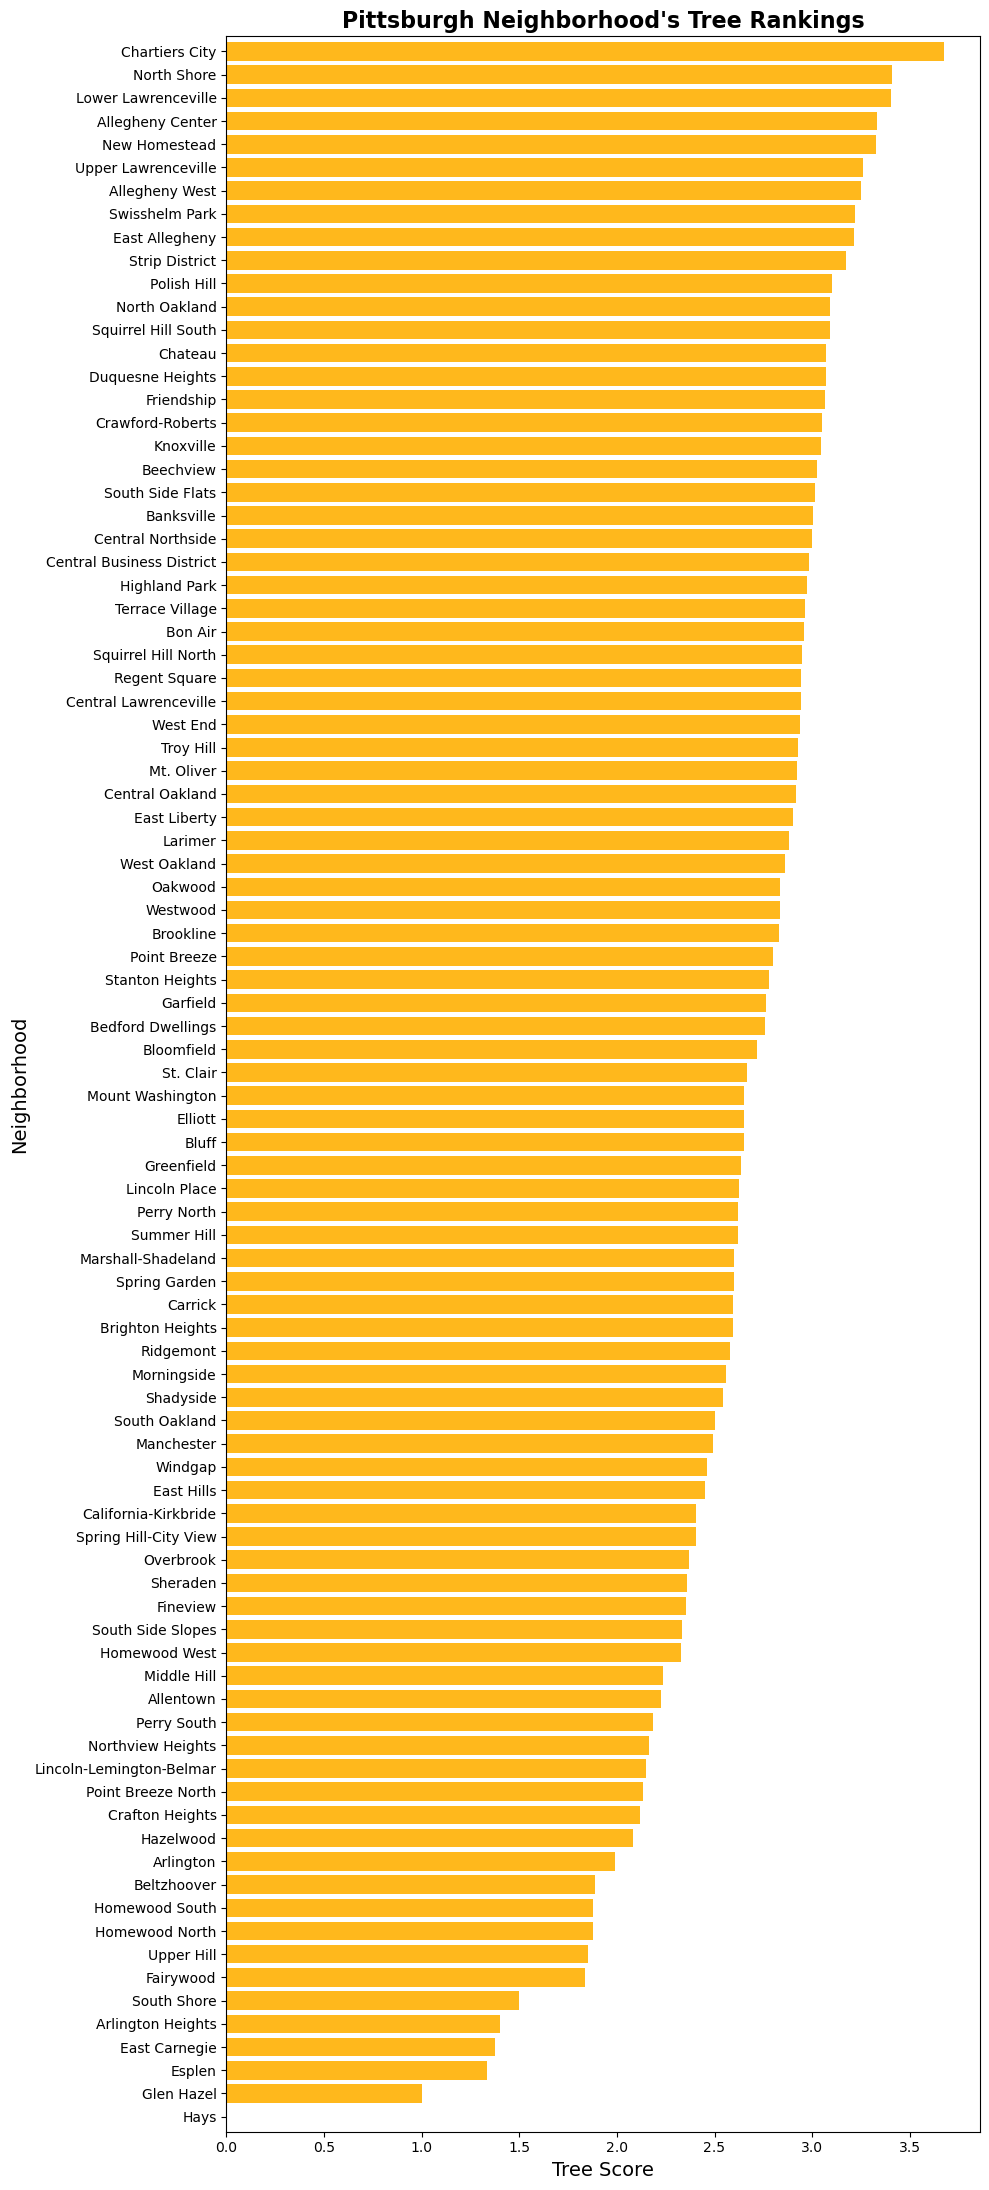

In [15]:
import pandas as pd
import matplotlib.pyplot as plt


source_map = { 
    "Excellent" : 6,
    "Very Good" : 5,
    "Good" : 4,
    "Fair" : 3,
    "Poor" : 2,
    "Critical" : 1,
    "Dead" : 0,
}
total = {}

for neighbor in df["neighborhood"].dropna().unique():
    total[neighbor] = 0

for index, row in df.iterrows():
    neighbor = row["neighborhood"]
    conditions = row["condition"]

    if neighbor not in total:
        continue


    if conditions == "Excellent":
        total[neighbor] = total[neighbor]+6
    elif conditions == "Very Good":  
        total[neighbor] = total[neighbor]+5
    elif conditions == "Good":
        total[neighbor] = total[neighbor]+4
    elif conditions == "Fair":
        total[neighbor] = total[neighbor]+3
    elif conditions == "Poor":
        total[neighbor] = total[neighbor]+2
    elif conditions == "Critical":
        total[neighbor] = total[neighbor]+1
    elif conditions == "Dead":
        total[neighbor] = total[neighbor]+0
    else:
        continue 

trees_per_neighborhood = df["neighborhood"].value_counts()
fin = {}
for place, count in trees_per_neighborhood.items():
    if place in total and count > 0:
        fin[place] = total[place]/count

print("Number of neighborhoods found:", len(fin))

pd.Series(fin).sort_values(ascending=True).plot(kind='barh', figsize=(10, 22), color='#FFB81C', width=0.8)
plt.xlabel("Tree Score", fontsize=14)
plt.ylabel("Neighborhood", fontsize=14)
plt.title("Pittsburgh Neighborhood's Tree Rankings", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()


